In [1]:
from pathlib import Path

def parse_mri_directory(root_dir):
    
    root_path = Path(root_dir)
    
    # 1. Extraire les dossiers (qui sont nos classes) et les trier.
    # Le tri (sorted) est STRICTEMENT OBLIGATOIRE. Sinon, 'glioma' pourrait être 
    # la classe 0 dans le train set, et la classe 2 dans le test set selon l'OS.
    classes = sorted([d.name for d in root_path.iterdir() if d.is_dir()])
    
    # 2. Créer le dictionnaire de correspondance : {'glioma': 0, 'meningioma': 1, ...}
    class_to_idx = {cls_name: idx for idx, cls_name in enumerate(classes)}
    
    dataset_index = []
    
    # 3. Parcourir chaque sous-dossier pour lister les chemins des images
    for cls_name in classes:
        class_dir = root_path / cls_name
        
        # On cherche toutes les images (ex: .jpg, .png, .jpeg)
        for ext in ('*.jpg', '*.jpeg', '*.png'):
            for img_path in class_dir.glob(ext):
                # On stocke uniquement le chemin (string) et l'entier de la classe
                dataset_index.append((str(img_path), class_to_idx[cls_name]))
                
    return dataset_index, class_to_idx, classes


In [4]:
index_train, mapping_train, classes_train = parse_mri_directory("Data/Training/")
index_test, mapping_test, classes_test = parse_mri_directory("Data/Testing/")

In [5]:
import torch
from torch.utils.data import Dataset
from PIL import Image
import torchvision.transforms as transforms

class MRIDataset(Dataset):
    def __init__(self, index_list, transform=None):
        """
        index_list : La liste de tuples (chemin, label) générée par le parser.
        transform : Les transformations PyTorch (redimensionnement, conversion tenseur, etc.)
        """
        self.index_list = index_list
        self.transform = transform

    def __len__(self):
        # PyTorch a besoin de savoir combien d'échantillons existent pour calculer les époques
        return len(self.index_list)

    def __getitem__(self, idx):
        # 1. Récupérer le chemin et le label pour l'index demandé
        img_path, label = self.index_list[idx]
        
        # 2. Charger l'image en mémoire vive UNIQUEMENT quand elle est demandée
        # Le .convert('RGB') est critique : certaines IRM peuvent être en niveaux 
        # de gris (1 canal) et d'autres en couleur (3 canaux). Cela force 3 canaux.
        image = Image.open(img_path).convert('RGB')
        
        # 3. Appliquer les transformations mathématiques (Tenseur, Normalisation)
        if self.transform:
            image = self.transform(image)
            
        # On s'assure que le label est bien un tenseur d'entier (long) 
        # requis par la fonction de perte CrossEntropyLoss
        label = torch.tensor(label, dtype=torch.long)
        
        return image, label

In [6]:
import torchvision.transforms as transforms

# 1. Transform pour l'ENTRAÎNEMENT (Avec injection de bruit géométrique)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5), # Retourne l'image 1 fois sur 2
    transforms.RandomRotation(degrees=15),  # Tourne l'image aléatoirement jusqu'à 15 degrés
    transforms.ColorJitter(brightness=0.1, contrast=0.1), # Légère variation de contraste (typique des IRM)
    transforms.ToTensor()
])

# 2. Transform pour le TEST (Strictement déterministe)
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# Mise à jour de l'instanciation (Attention à bien passer les bonnes variables)
train_dataset = MRIDataset(index_list=index_train, transform=train_transform)
test_dataset = MRIDataset(index_list=index_test, transform=test_transform)

In [7]:
from torch.utils.data import DataLoader


# 2. Paramétrage rigoureux des DataLoaders
BATCH_SIZE = 32

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,       # Indispensable pour le train : casse l'ordre temporel des données
    num_workers=4,      # Nombre de cœurs CPU alloués au chargement des images
    pin_memory=True     # Accélère drastiquement le transfert de la RAM (CPU) vers la VRAM (GPU)
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,      # Strictement False pour le test : l'ordre n'a pas d'importance pour l'évaluation
    num_workers=4,
    pin_memory=True
)

In [8]:
import torch.nn as nn
import torch.nn.functional as F

class MRITumorClassifier(nn.Module):
    def __init__(self):
        super(MRITumorClassifier, self).__init__()
        
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.pool1 = nn.MaxPool2d(2, 2) 
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.pool2 = nn.MaxPool2d(2, 2)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool3 = nn.MaxPool2d(2, 2)

        # Nouvelle couche : Le Dropout
        self.dropout = nn.Dropout(p=0.5)
        
        self.fc1 = nn.Linear(64 * 28 * 28, 128)
        self.fc2 = nn.Linear(128, 4) 
        
    def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool2(F.relu(self.conv2(x)))
        x = self.pool3(F.relu(self.conv3(x)))
        
        x = x.view(-1, 64 * 28 * 28)
        
        # Injection du Dropout AVANT et APRÈS la première couche dense
        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        
        x = self.fc2(x) 
        return x

# Instanciation du modèle
model = MRITumorClassifier()
print(model)

MRITumorClassifier(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=50176, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=4, bias=True)
)


In [9]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Gestion stricte du matériel (Device)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
print(f"Modèle et calculs assignés sur : {device}")

# 2. La fonction de coût (Loss)
criterion = nn.CrossEntropyLoss()

# 3. L'optimiseur
LEARNING_RATE = 1e-3  # 0.001 est un standard robuste pour démarrer avec Adam
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

Modèle et calculs assignés sur : cpu


In [23]:
from tqdm import tqdm
import torch
import numpy as np

EPOCHS = 10

# CORRECTION STRICTE : La variable doit exister en mémoire avant que la boucle ne démarre.
best_test_loss = float('inf')

for epoch in range(EPOCHS):
    
    # ==========================================
    # 1. PHASE D'ENTRAÎNEMENT
    # ==========================================
    model.train() # Active le calcul des gradients et les comportements spécifiques (Dropout/BatchNorm)
    
    running_train_loss = 0.0
    correct_train = 0
    total_train = 0
    
    # Barre de progression pour le batch
    train_loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]", leave=False)
    
    for images, labels in train_loop:
        # TRANSFERT MATÉRIEL : Déplacer les données sur le même device (GPU) que le modèle
        images = images.to(device)
        labels = labels.to(device)
        
        # FORWARD PASS
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # BACKWARD PASS
        optimizer.zero_grad() # DANGER : Toujours réinitialiser avant backward()
        loss.backward()
        optimizer.step()
        
        # CALCUL DES MÉTRIQUES
        _, predicted = torch.max(outputs.data, 1)
        
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        
        # Multiplication par la taille du batch pour annuler la moyenne automatique de PyTorch
        running_train_loss += loss.item() * images.size(0)
        
        # Mise à jour visuelle de la barre de progression
        train_loop.set_postfix(loss=loss.item(), acc=100. * correct_train / total_train)

    epoch_train_loss = running_train_loss / len(train_dataset)
    epoch_train_acc = 100. * correct_train / total_train

    # ==========================================
    # 2. PHASE DE VALIDATION / TEST
    # ==========================================
    model.eval() # Fige le réseau (désactive Dropout)
    
    running_test_loss = 0.0
    correct_test = 0
    total_test = 0
    
    with torch.no_grad(): # CRITIQUE : Désactive le stockage du graphe de calcul
        test_loop = tqdm(test_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Test] ", leave=False)
        for images, labels in test_loop:
            images = images.to(device)
            labels = labels.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            _, predicted = torch.max(outputs.data, 1)
            total_test += labels.size(0)
            correct_test += (predicted == labels).sum().item()
            running_test_loss += loss.item() * images.size(0)

    epoch_test_loss = running_test_loss / len(test_dataset)
    epoch_test_acc = 100. * correct_test / total_test


    # ==========================================
    # 3. CHECKPOINTING ET BILAN DE L'ÉPOQUE
    # ==========================================
    if epoch_test_loss < best_test_loss:
        print(f"  => [AMÉLIORATION] Test Loss a diminué ({best_test_loss:.4f} -> {epoch_test_loss:.4f}). Sauvegarde des poids !")
        best_test_loss = epoch_test_loss
        # Sauvegarde d'un dictionnaire contenant la valeur exacte des poids et biais
        torch.save(model.state_dict(), 'meilleur_modele_mri.pth')

    print(f"Epoch {epoch+1:02d}/{EPOCHS} | "
          f"Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc:.2f}% | "
          f"Test Loss: {epoch_test_loss:.4f} - Test Acc: {epoch_test_acc:.2f}%")

Epoch 1/10 [Train]:   0%|          | 0/175 [00:00<?, ?it/s]/home/ensai/.local/lib/python3.10/site-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  => [AMÉLIORATION] Test Loss a diminué (inf -> 0.8739). Sauvegarde des poids !
Epoch 01/10 | Train Loss: 0.8686 - Train Acc: 65.21% | Test Loss: 0.8739 - Test Acc: 68.50%


  => [AMÉLIORATION] Test Loss a diminué (0.8739 -> 0.8590). Sauvegarde des poids !
Epoch 02/10 | Train Loss: 0.6324 - Train Acc: 74.57% | Test Loss: 0.8590 - Test Acc: 72.62%


Epoch 03/10 | Train Loss: 0.5457 - Train Acc: 79.20% | Test Loss: 0.9294 - Test Acc: 74.38%


  => [AMÉLIORATION] Test Loss a diminué (0.8590 -> 0.8408). Sauvegarde des poids !
Epoch 04/10 | Train Loss: 0.5107 - Train Acc: 80.00% | Test Loss: 0.8408 - Test Acc: 78.50%


...

  => [AMÉLIORATION] Test Loss a diminué (0.7991 -> 0.7078). Sauvegarde des poids !
Epoch 06/10 | Train Loss: 0.4118 - Train Acc: 83.80% | Test Loss: 0.7078 - Test Acc: 80.56%


Epoch 07/10 | Train Loss: 0.3820 - Train Acc: 85.05% | Test Loss: 0.7568 - Test Acc: 81.94%


Epoch 08/10 | Train Loss: 0.3556 - Train Acc: 86.77% | Test Loss: 0.8169 - Test Acc: 81.44%


  => [AMÉLIORATION] Test Loss a diminué (0.7078 -> 0.6335). Sauvegarde des poids !
Epoch 09/10 | Train Loss: 0.3378 - Train Acc: 86.66% | Test Loss: 0.6335 - Test Acc: 85.12%


Epoch 10/10 | Train Loss: 0.3082 - Train Acc: 88.29% | Test Loss: 0.7947 - Test Acc: 84.75%


In [25]:
pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


=== RAPPORT DE CLASSIFICATION ===
              precision    recall  f1-score   support

      glioma       0.92      0.67      0.78       400
  meningioma       0.78      0.77      0.78       400
     notumor       0.82      0.97      0.89       400
   pituitary       0.90      0.99      0.95       400

    accuracy                           0.85      1600
   macro avg       0.86      0.85      0.85      1600
weighted avg       0.86      0.85      0.85      1600



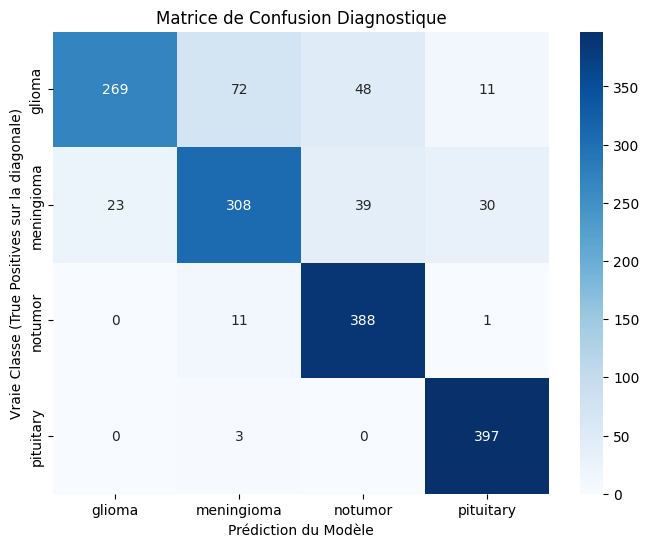

In [27]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

classes = ['glioma', 'meningioma', 'notumor', 'pituitary']
# 1. Charger les poids optimaux garantis par le Checkpoint
# (Assure-toi d'avoir instancié le modèle et le device avant)
model.load_state_dict(torch.load('meilleur_modele_mri.pth'))
model.eval() # Coupe le Dropout, crucial pour l'inférence

y_true = []
y_pred = []

# 2. Collecter les prédictions sans calculer de gradients
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        
        # On rapatrie les tenseurs sur le CPU et on les convertit en listes Numpy
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

# 3. Le diagnostic analytique
print("=== RAPPORT DE CLASSIFICATION ===")
print(classification_report(y_true, y_pred, target_names=classes))

# 4. Visualisation de la Matrice de Confusion
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.ylabel('Vraie Classe (True Positives sur la diagonale)')
plt.xlabel('Prédiction du Modèle')
plt.title('Matrice de Confusion Diagnostique')
plt.show()

In [10]:

import torchvision.models as models

# ==========================================
# 3. ARCHITECTURE DU MODÈLE (Transfer Learning avec ResNet18)
# ==========================================
print("Téléchargement des poids ImageNet pour ResNet18...")
# On charge l'architecture ResNet18 avec ses poids optimaux
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# VERROUILLAGE (Freezing) : On gèle toutes les couches convolutives
# Le réseau a déjà appris à extraire des textures sur ImageNet, on préserve ce savoir.
for param in model.parameters():
    param.requires_grad = False

# RECONSTRUCTION DE LA TÊTE (Classification Head)
# On récupère le nombre de neurones qui entrent dans la toute dernière couche
num_features = model.fc.in_features

# On remplace l'ancienne couche (1000 classes) par notre nouvelle couche (4 classes)
# Par défaut dans PyTorch, les nouvelles couches ont 'requires_grad = True'
model.fc = nn.Linear(num_features, 4)


# ==========================================
# 4. PRÉPARATION DE L'ENTRAÎNEMENT (Loss pondérée & Optimiseur ciblé)
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# PONDÉRATION DE LA LOSS (Correction du biais)
# Ordre des classes : [glioma (0), meningioma (1), notumor (2), pituitary (3)]
# On force le réseau à faire très attention au Gliome (x3) et au Méningiome (x2)
poids_classes = torch.tensor([3.0, 2.0, 1.0, 1.0], dtype=torch.float).to(device)
criterion = nn.CrossEntropyLoss(weight=poids_classes)

# OPTIMISEUR STRICTEMENT CIBLÉ
# ATTENTION : On ne passe PLUS 'model.parameters()'.
# On indique à l'optimiseur de ne mettre à jour QUE les poids de notre nouvelle couche 'fc'.
optimizer = optim.Adam(model.fc.parameters(), lr=1e-3, weight_decay=1e-4)

print(f"Modèle assigné sur : {device}")

Téléchargement des poids ImageNet pour ResNet18...
Modèle assigné sur : cpu


In [ ]:
from tqdm import tqdm
import torch
import numpy as np

EPOCHS = 10

# CORRECTION STRICTE : La variable doit exister en mémoire avant que la boucle ne démarre.
best_test_loss = float('inf')

for epoch in range(EPOCHS):
    
    # ==========================================
    # 1. PHASE D'ENTRAÎNEMENT
    # ==========================================
    model.train() # Active le calcul des gradients et les comportements spécifiques (Dropout/BatchNorm)
    
    running_train_loss = 0.0
    correct_train = 0
    total_train = 0
    
    # Barre de progression pour le batch
    train_loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]", leave=False)
    
    for images, labels in train_loop:
        # TRANSFERT MATÉRIEL : Déplacer les données sur le même device (GPU) que le modèle
        images = images.to(device)
        labels = labels.to(device)
        
        # FORWARD PASS
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # BACKWARD PASS
        optimizer.zero_grad() # DANGER : Toujours réinitialiser avant backward()
        loss.backward()
        optimizer.step()
        
        # CALCUL DES MÉTRIQUES
        _, predicted = torch.max(outputs.data, 1)
        
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        
        # Multiplication par la taille du batch pour annuler la moyenne automatique de PyTorch
        running_train_loss += loss.item() * images.size(0)
        
        # Mise à jour visuelle de la barre de progression
        train_loop.set_postfix(loss=loss.item(), acc=100. * correct_train / total_train)

    epoch_train_loss = running_train_loss / len(train_dataset)
    epoch_train_acc = 100. * correct_train / total_train

    # ==========================================
    # 2. PHASE DE VALIDATION / TEST
    # ==========================================
    model.eval() # Fige le réseau (désactive Dropout)
    
    running_test_loss = 0.0
    correct_test = 0
    total_test = 0
    
    with torch.no_grad(): # CRITIQUE : Désactive le stockage du graphe de calcul
        test_loop = tqdm(test_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Test] ", leave=False)
        for images, labels in test_loop:
            images = images.to(device)
            labels = labels.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            _, predicted = torch.max(outputs.data, 1)
            total_test += labels.size(0)
            correct_test += (predicted == labels).sum().item()
            running_test_loss += loss.item() * images.size(0)

    epoch_test_loss = running_test_loss / len(test_dataset)
    epoch_test_acc = 100. * correct_test / total_test


    # ==========================================
    # 3. CHECKPOINTING ET BILAN DE L'ÉPOQUE
    # ==========================================
    if epoch_test_loss < best_test_loss:
        print(f"  => [AMÉLIORATION] Test Loss a diminué ({best_test_loss:.4f} -> {epoch_test_loss:.4f}). Sauvegarde des poids !")
        best_test_loss = epoch_test_loss
        # Sauvegarde d'un dictionnaire contenant la valeur exacte des poids et biais
        torch.save(model.state_dict(), 'meilleur_modele_mri.pth')

    print(f"Epoch {epoch+1:02d}/{EPOCHS} | "
          f"Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc:.2f}% | "
          f"Test Loss: {epoch_test_loss:.4f} - Test Acc: {epoch_test_acc:.2f}%")

Epoch 1/10 [Train]:   0%|          | 0/175 [00:00<?, ?it/s]/home/ensai/.local/lib/python3.10/site-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  => [AMÉLIORATION] Test Loss a diminué (inf -> 0.6698). Sauvegarde des poids !
Epoch 01/10 | Train Loss: 0.7194 - Train Acc: 69.11% | Test Loss: 0.6698 - Test Acc: 72.25%


  => [AMÉLIORATION] Test Loss a diminué (0.6698 -> 0.5524). Sauvegarde des poids !
Epoch 02/10 | Train Loss: 0.5086 - Train Acc: 80.54% | Test Loss: 0.5524 - Test Acc: 78.94%


  => [AMÉLIORATION] Test Loss a diminué (0.5524 -> 0.5218). Sauvegarde des poids !
Epoch 03/10 | Train Loss: 0.4394 - Train Acc: 83.23% | Test Loss: 0.5218 - Test Acc: 81.12%


Epoch 04/10 | Train Loss: 0.4193 - Train Acc: 83.57% | Test Loss: 0.5515 - Test Acc: 79.94%


...

  => [AMÉLIORATION] Test Loss a diminué (0.5218 -> 0.5042). Sauvegarde des poids !
Epoch 06/10 | Train Loss: 0.3714 - Train Acc: 85.57% | Test Loss: 0.5042 - Test Acc: 80.50%


  => [AMÉLIORATION] Test Loss a diminué (0.5042 -> 0.4920). Sauvegarde des poids !
Epoch 07/10 | Train Loss: 0.3706 - Train Acc: 85.91% | Test Loss: 0.4920 - Test Acc: 83.06%


Epoch 08/10 | Train Loss: 0.3739 - Train Acc: 85.00% | Test Loss: 0.5362 - Test Acc: 81.94%


Epoch 09/10 | Train Loss: 0.3686 - Train Acc: 85.86% | Test Loss: 0.5092 - Test Acc: 81.75%


Epoch 10/10 | Train Loss: 0.3507 - Train Acc: 86.84% | Test Loss: 0.4994 - Test Acc: 83.06%


=== RAPPORT DE CLASSIFICATION RESNET ===
              precision    recall  f1-score   support

      glioma       0.84      0.76      0.80       400
  meningioma       0.72      0.73      0.72       400
     notumor       0.85      0.97      0.91       400
   pituitary       0.92      0.86      0.89       400

    accuracy                           0.83      1600
   macro avg       0.83      0.83      0.83      1600
weighted avg       0.83      0.83      0.83      1600



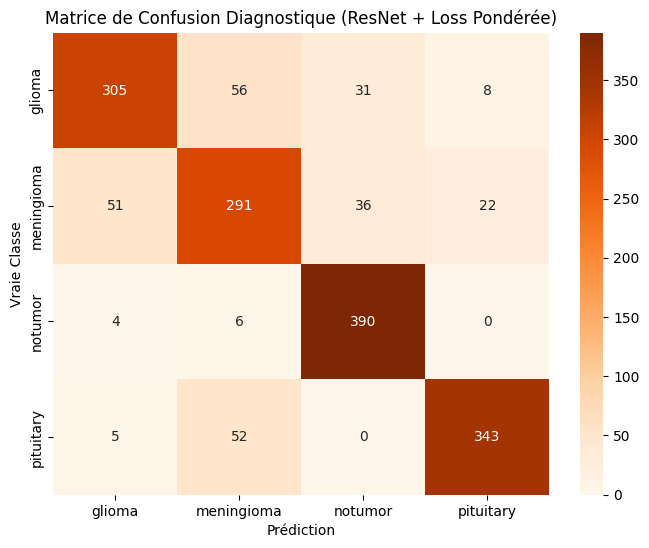

In [31]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 1. Chargement rigoureux des poids de l'époque 7
model.load_state_dict(torch.load('meilleur_modele_mri.pth'))
model.eval()

y_true = []
y_pred = []

# 2. Inférence silencieuse
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

# 3. Récupération des classes et rapport
classes = ['glioma', 'meningioma', 'notumor', 'pituitary']

print("=== RAPPORT DE CLASSIFICATION RESNET ===")
print(classification_report(y_true, y_pred, target_names=classes))

# 4. Matrice comparative
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=classes, yticklabels=classes)
plt.ylabel('Vraie Classe')
plt.xlabel('Prédiction')
plt.title('Matrice de Confusion Diagnostique (ResNet + Loss Pondérée)')
plt.show()

In [11]:
import torchvision.models as models
import torch.optim as optim
import torch.nn as nn
import torch

# ==========================================
# 3. ARCHITECTURE ET FINE-TUNING CIBLÉ
# ==========================================
print("Chargement de ResNet18 et déblocage partiel...")
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# 1. On gèle TOUT le réseau par sécurité initiale
for param in model.parameters():
    param.requires_grad = False

# 2. On débloque STRICTEMENT le dernier bloc de convolution (layer4)
for param in model.layer4.parameters():
    param.requires_grad = True

# 3. On remplace la tête (elle a requires_grad=True par défaut)
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 4)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)


# ==========================================
# 4. PRÉPARATION DE L'ENTRAÎNEMENT (Differential Learning Rate)
# ==========================================
# On conserve notre matrice de poids pour forcer l'attention sur le Gliome
poids_classes = torch.tensor([3.0, 2.0, 1.0, 1.0], dtype=torch.float).to(device)
criterion = nn.CrossEntropyLoss(weight=poids_classes)

# L'OPTIMISEUR AVANCÉ (Le secret du Fine-Tuning)
# Au lieu de donner un seul Learning Rate, on passe une liste de dictionnaires.
optimizer = optim.Adam([
    # Pour layer4 : Taux microscopique (1e-5). 
    # But : "Masser" les poids ImageNet existants sans les détruire (Catastrophic Forgetting).
    {'params': model.layer4.parameters(), 'lr': 1e-5},
    
    # Pour fc : Taux classique (1e-3).
    # But : Entraîner rapidement cette nouvelle couche qui part de zéro.
    {'params': model.fc.parameters(), 'lr': 1e-3}
], weight_decay=1e-4)

print(f"Modèle assigné sur : {device} avec Differential Learning Rate activé.")

Chargement de ResNet18 et déblocage partiel...
Modèle assigné sur : cpu avec Differential Learning Rate activé.


In [33]:
from tqdm import tqdm
import torch
import numpy as np

EPOCHS = 10

# CORRECTION STRICTE : La variable doit exister en mémoire avant que la boucle ne démarre.
best_test_loss = float('inf')

for epoch in range(EPOCHS):
    
    # ==========================================
    # 1. PHASE D'ENTRAÎNEMENT
    # ==========================================
    model.train() # Active le calcul des gradients et les comportements spécifiques (Dropout/BatchNorm)
    
    running_train_loss = 0.0
    correct_train = 0
    total_train = 0
    
    # Barre de progression pour le batch
    train_loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]", leave=False)
    
    for images, labels in train_loop:
        # TRANSFERT MATÉRIEL : Déplacer les données sur le même device (GPU) que le modèle
        images = images.to(device)
        labels = labels.to(device)
        
        # FORWARD PASS
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # BACKWARD PASS
        optimizer.zero_grad() # DANGER : Toujours réinitialiser avant backward()
        loss.backward()
        optimizer.step()
        
        # CALCUL DES MÉTRIQUES
        _, predicted = torch.max(outputs.data, 1)
        
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        
        # Multiplication par la taille du batch pour annuler la moyenne automatique de PyTorch
        running_train_loss += loss.item() * images.size(0)
        
        # Mise à jour visuelle de la barre de progression
        train_loop.set_postfix(loss=loss.item(), acc=100. * correct_train / total_train)

    epoch_train_loss = running_train_loss / len(train_dataset)
    epoch_train_acc = 100. * correct_train / total_train

    # ==========================================
    # 2. PHASE DE VALIDATION / TEST
    # ==========================================
    model.eval() # Fige le réseau (désactive Dropout)
    
    running_test_loss = 0.0
    correct_test = 0
    total_test = 0
    
    with torch.no_grad(): # CRITIQUE : Désactive le stockage du graphe de calcul
        test_loop = tqdm(test_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Test] ", leave=False)
        for images, labels in test_loop:
            images = images.to(device)
            labels = labels.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            _, predicted = torch.max(outputs.data, 1)
            total_test += labels.size(0)
            correct_test += (predicted == labels).sum().item()
            running_test_loss += loss.item() * images.size(0)

    epoch_test_loss = running_test_loss / len(test_dataset)
    epoch_test_acc = 100. * correct_test / total_test


    # ==========================================
    # 3. CHECKPOINTING ET BILAN DE L'ÉPOQUE
    # ==========================================
    if epoch_test_loss < best_test_loss:
        print(f"  => [AMÉLIORATION] Test Loss a diminué ({best_test_loss:.4f} -> {epoch_test_loss:.4f}). Sauvegarde des poids !")
        best_test_loss = epoch_test_loss
        # Sauvegarde d'un dictionnaire contenant la valeur exacte des poids et biais
        torch.save(model.state_dict(), 'meilleur_modele_mri.pth')

    print(f"Epoch {epoch+1:02d}/{EPOCHS} | "
          f"Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc:.2f}% | "
          f"Test Loss: {epoch_test_loss:.4f} - Test Acc: {epoch_test_acc:.2f}%")

Epoch 1/10 [Train]:   0%|          | 0/175 [00:00<?, ?it/s]/home/ensai/.local/lib/python3.10/site-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  => [AMÉLIORATION] Test Loss a diminué (inf -> 0.5543). Sauvegarde des poids !
Epoch 01/10 | Train Loss: 0.5589 - Train Acc: 76.38% | Test Loss: 0.5543 - Test Acc: 79.50%


  => [AMÉLIORATION] Test Loss a diminué (0.5543 -> 0.4053). Sauvegarde des poids !
Epoch 02/10 | Train Loss: 0.3201 - Train Acc: 87.41% | Test Loss: 0.4053 - Test Acc: 87.31%


Epoch 03/10 | Train Loss: 0.2526 - Train Acc: 91.00% | Test Loss: 0.4093 - Test Acc: 88.06%


Epoch 04/10 | Train Loss: 0.1971 - Train Acc: 92.91% | Test Loss: 0.4113 - Test Acc: 90.25%


...

  => [AMÉLIORATION] Test Loss a diminué (0.4053 -> 0.3943). Sauvegarde des poids !
Epoch 06/10 | Train Loss: 0.1438 - Train Acc: 94.71% | Test Loss: 0.3943 - Test Acc: 91.75%


  => [AMÉLIORATION] Test Loss a diminué (0.3943 -> 0.3759). Sauvegarde des poids !
Epoch 07/10 | Train Loss: 0.1316 - Train Acc: 95.55% | Test Loss: 0.3759 - Test Acc: 92.62%


Epoch 08/10 | Train Loss: 0.1049 - Train Acc: 96.12% | Test Loss: 0.4443 - Test Acc: 91.62%


Epoch 09/10 | Train Loss: 0.0857 - Train Acc: 96.91% | Test Loss: 0.4089 - Test Acc: 93.12%


Epoch 10/10 | Train Loss: 0.0852 - Train Acc: 96.84% | Test Loss: 0.3926 - Test Acc: 93.19%


=== RAPPORT DE CLASSIFICATION RESNET ===
              precision    recall  f1-score   support

      glioma       0.96      0.80      0.87       400
  meningioma       0.86      0.94      0.90       400
     notumor       0.93      0.99      0.96       400
   pituitary       0.97      0.97      0.97       400

    accuracy                           0.93      1600
   macro avg       0.93      0.93      0.93      1600
weighted avg       0.93      0.93      0.93      1600



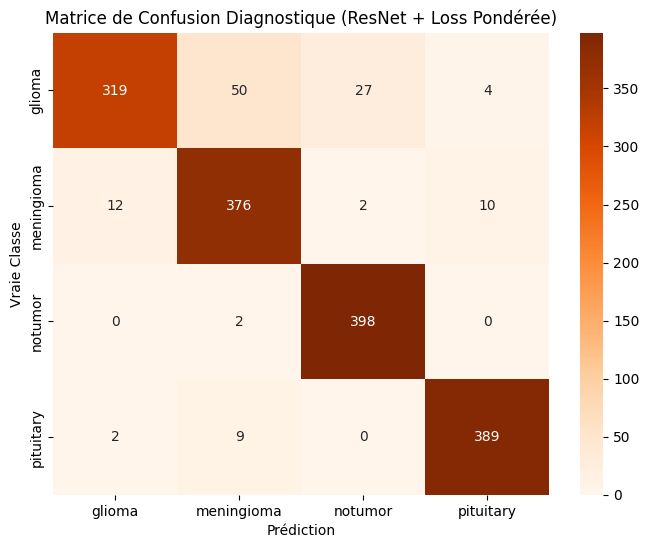

In [34]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 1. Chargement rigoureux des poids de l'époque 7
model.load_state_dict(torch.load('meilleur_modele_mri.pth'))
model.eval()

y_true = []
y_pred = []

# 2. Inférence silencieuse
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

# 3. Récupération des classes et rapport
classes = ['glioma', 'meningioma', 'notumor', 'pituitary']

print("=== RAPPORT DE CLASSIFICATION RESNET ===")
print(classification_report(y_true, y_pred, target_names=classes))

# 4. Matrice comparative
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=classes, yticklabels=classes)
plt.ylabel('Vraie Classe')
plt.xlabel('Prédiction')
plt.title('Matrice de Confusion Diagnostique (ResNet + Loss Pondérée)')
plt.show()

In [35]:
pip install grad-cam

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 KB 300.2 kB/s eta 0:00:00a 0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 MB 299.1 kB/s eta 0:00:0000:0100:06
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53267 sha256=89df9c79457267582752f0219cc5e4d1f5bf86e69dbb143f4de3e7a954a94dad
  Stored in directory: /home/ensai/.cache/pip/wheels/3b/c5/76/c687e07554662415de61a0cf44f13f76c4a70b9c1f59b69de9
Successfully built grad-cam
Note: you may need to restart the kernel to use updated packages.


/home/ensai/.local/lib/python3.10/site-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Vraie classe : glioma | Prédiction : meningioma


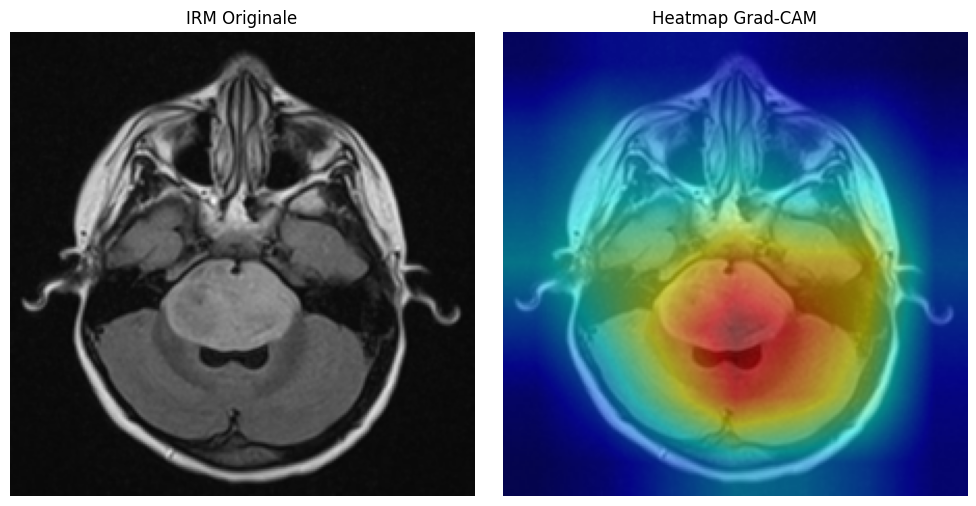

In [36]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
import matplotlib.pyplot as plt
import torch

# 1. Cibler la couche d'extraction des caractéristiques spatiales
# C'est la couche exacte que nous avons fine-tunée (layer4)
target_layers = [model.layer4[-1]]

# 2. Initialiser le mécanisme Grad-CAM
cam = GradCAM(model=model, target_layers=target_layers)

# 3. Prélever un batch du DataLoader de test
model.eval()
images, labels = next(iter(test_loader))

# On isole la toute première image du batch
image_tensor = images[0].unsqueeze(0).to(device)
vraie_classe_idx = labels[0].item()

# 4. Inférence (Que prédit le modèle ?)
with torch.no_grad():
    outputs = model(image_tensor)
    _, predicted_idx = torch.max(outputs, 1)

classes = ['glioma', 'meningioma', 'notumor', 'pituitary']
print(f"Vraie classe : {classes[vraie_classe_idx]} | Prédiction : {classes[predicted_idx.item()]}")

# 5. Générer la carte de gradients pour la classe prédite
# On demande au modèle : "Quels pixels t'ont poussé à choisir cette classe ?"
targets = [ClassifierOutputTarget(predicted_idx.item())]
grayscale_cam = cam(input_tensor=image_tensor, targets=targets)[0, :]

# 6. Conversion du tenseur mathématique en image visuelle
# PyTorch utilise [Canaux, Hauteur, Largeur]. Matplotlib veut [Hauteur, Largeur, Canaux]
rgb_img = image_tensor[0].cpu().numpy().transpose(1, 2, 0)

# Superposition de la Heatmap (en format RGB)
visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

# 7. Affichage
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(rgb_img)
ax[0].set_title("IRM Originale")
ax[0].axis('off')

ax[1].imshow(visualization)
ax[1].set_title("Heatmap Grad-CAM")
ax[1].axis('off')

plt.tight_layout()
plt.show()

In [37]:
import cv2
import numpy as np
from PIL import Image

def auto_crop_mri(image_path):
    # 1. Chargement de l'image (OpenCV lit en BGR)
    img = cv2.imread(image_path)
    if img is None:
        raise ValueError(f"Erreur de lecture OpenCV sur : {image_path}")
        
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    # 2. Floutage Gaussien (Élimine le bruit statique de la machine IRM)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    
    # 3. Seuillage (Thresholding) : Tout pixel > 45 devient blanc (255), le reste devient noir (0)
    _, thresh = cv2.threshold(blurred, 45, 255, cv2.THRESH_BINARY)
    
    # 4. Fermeture morphologique : Érosion puis Dilatation
    # Permet de boucher les "trous" noirs à l'intérieur du crâne pour unifier le contour
    thresh = cv2.erode(thresh, None, iterations=2)
    thresh = cv2.dilate(thresh, None, iterations=2)
    
    # 5. Détection des contours mathématiques
    contours, _ = cv2.findContours(thresh.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if contours:
        # 6. Isoler le plus grand contour (la masse crânienne)
        c = max(contours, key=cv2.contourArea)
        
        # 7. Calculer la boîte englobante (Bounding Box)
        x, y, w, h = cv2.boundingRect(c)
        
        # 8. Recadrage strict (Cropping) par slicing de matrice NumPy
        cropped_img = img[y:y+h, x:x+w]
    else:
        cropped_img = img # Sécurité : on garde l'original si aucun contour n'est trouvé
        
    # 9. Conversion OpenCV (BGR) vers PIL (RGB) pour la compatibilité avec PyTorch
    cropped_img_rgb = cv2.cvtColor(cropped_img, cv2.COLOR_BGR2RGB)
    return Image.fromarray(cropped_img_rgb)

In [38]:
class MRIDataset(Dataset):
    def __init__(self, index_list, transform=None):
        self.index_list = index_list
        self.transform = transform

    def __len__(self):
        return len(self.index_list)

    def __getitem__(self, idx):
        img_path, label = self.index_list[idx]
        
        # REMPLACEMENT ICI : On utilise notre Auto-Cropper OpenCV
        # Au lieu de : image = Image.open(img_path).convert('RGB')
        image = auto_crop_mri(img_path)
        
        if self.transform:
            image = self.transform(image)
            
        label = torch.tensor(label, dtype=torch.long)
        return image, label

Fichier ciblé : Data/Training/meningioma/Tr-me_1059.jpg


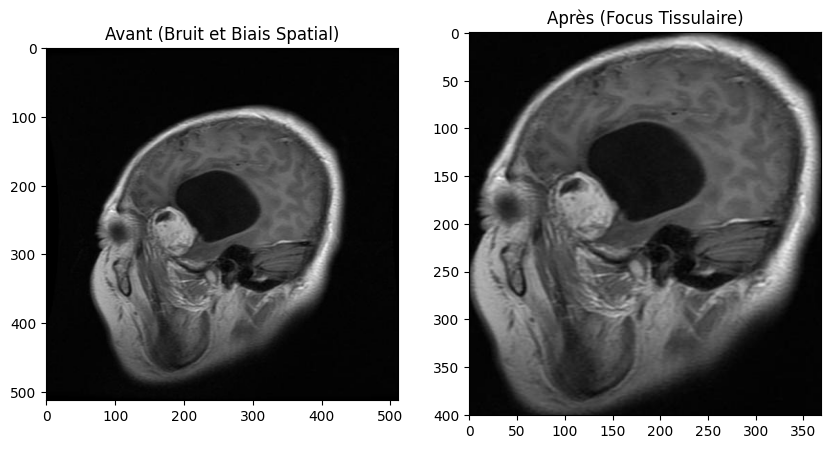

In [40]:
import matplotlib.pyplot as plt
import cv2
from pathlib import Path

# 1. Cibler dynamiquement la première image du dossier
dossier_meningioma = Path("Data/Training/meningioma")
# Récupère le premier fichier .jpg ou .png trouvé dans le dossier
image_test = str(list(dossier_meningioma.glob("*.jpg"))[0]) 

print(f"Fichier ciblé : {image_test}")

# 2. Extraction et conversion
img_originale = cv2.cvtColor(cv2.imread(image_test), cv2.COLOR_BGR2RGB)
img_recadree = auto_crop_mri(image_test)

# 3. Affichage comparatif
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img_originale)
ax[0].set_title("Avant (Bruit et Biais Spatial)")
ax[1].imshow(img_recadree)
ax[1].set_title("Après (Focus Tissulaire)")
plt.show()

In [45]:
import torchvision.models as models
import torch.optim as optim
import torch.nn as nn
import torch
from tqdm import tqdm

# ==========================================
# 1. RE-GÉNÉRATION DES DATALOADERS (Crucial)
# ==========================================
# En recréant les instances, PyTorch va utiliser la nouvelle version de ta classe MRIDataset
# qui contient l'appel à auto_crop_mri()
# CORRECTION : On passe les listes brutes, pas les loaders !
train_dataset = MRIDataset(index_list=index_train, transform=train_transform)
test_dataset = MRIDataset(index_list=index_test, transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# ==========================================
# 2. PURGE ET REINITIALISATION DU MODÈLE
# ==========================================
print("Chargement d'un ResNet18 vierge (Poids ImageNet purs)...")
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# Verrouillage global
for param in model.parameters():
    param.requires_grad = False

# Déblocage strict de layer4 (Fine-Tuning)
for param in model.layer4.parameters():
    param.requires_grad = True

# Reconstruction de la tête de décision
model.fc = nn.Linear(model.fc.in_features, 4)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# ==========================================
# 3. OPTIMISATION ET PERTE
# ==========================================
poids_classes = torch.tensor([3.0, 2.0, 1.0, 1.0], dtype=torch.float).to(device)
criterion = nn.CrossEntropyLoss(weight=poids_classes)

optimizer = optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-5},
    {'params': model.fc.parameters(), 'lr': 1e-3}
], weight_decay=1e-4)

# ==========================================
# 4. BOUCLE D'ENTRAÎNEMENT STRICTE
# ==========================================
EPOCHS = 10
best_test_loss = float('inf')

for epoch in range(EPOCHS):
    
    # Phase d'entraînement
    model.train() 
    running_train_loss, correct_train, total_train = 0.0, 0, 0
    
    train_loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]", leave=False)
    for images, labels in train_loop:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad() 
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        running_train_loss += loss.item() * images.size(0)
        train_loop.set_postfix(loss=loss.item())

    # Phase de test
    model.eval() 
    running_test_loss, correct_test, total_test = 0.0, 0, 0
    
    with torch.no_grad(): 
        test_loop = tqdm(test_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Test] ", leave=False)
        for images, labels in test_loop:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            _, predicted = torch.max(outputs.data, 1)
            total_test += labels.size(0)
            correct_test += (predicted == labels).sum().item()
            running_test_loss += loss.item() * images.size(0)

    # Calcul des métriques de l'époque
    epoch_train_loss = running_train_loss / len(train_dataset)
    epoch_train_acc = 100. * correct_train / total_train
    epoch_test_loss = running_test_loss / len(test_dataset)
    epoch_test_acc = 100. * correct_test / total_test

    # Checkpoint mathématique
    if epoch_test_loss < best_test_loss:
        print(f"  => [AMÉLIORATION] Test Loss ({best_test_loss:.4f} -> {epoch_test_loss:.4f}). Sauvegarde !")
        best_test_loss = epoch_test_loss
        torch.save(model.state_dict(), 'meilleur_modele_resnet_cropped.pth')

    print(f"Epoch {epoch+1:02d}/{EPOCHS} | Train Acc: {epoch_train_acc:.2f}% | Test Acc: {epoch_test_acc:.2f}% | Test Loss: {epoch_test_loss:.4f}")

Chargement d'un ResNet18 vierge (Poids ImageNet purs)...


  => [AMÉLIORATION] Test Loss (inf -> 0.5123). Sauvegarde !
Epoch 01/10 | Train Acc: 76.70% | Test Acc: 80.25% | Test Loss: 0.5123


  => [AMÉLIORATION] Test Loss (0.5123 -> 0.4377). Sauvegarde !
Epoch 02/10 | Train Acc: 87.82% | Test Acc: 86.06% | Test Loss: 0.4377


  => [AMÉLIORATION] Test Loss (0.4377 -> 0.3701). Sauvegarde !
Epoch 03/10 | Train Acc: 90.61% | Test Acc: 87.75% | Test Loss: 0.3701


  => [AMÉLIORATION] Test Loss (0.3701 -> 0.3679). Sauvegarde !
Epoch 04/10 | Train Acc: 92.39% | Test Acc: 88.75% | Test Loss: 0.3679


...

Epoch 06/10 | Train Acc: 93.95% | Test Acc: 89.50% | Test Loss: 0.3946


Epoch 07/10 | Train Acc: 95.18% | Test Acc: 91.00% | Test Loss: 0.4096


Epoch 08/10 | Train Acc: 95.20% | Test Acc: 90.56% | Test Loss: 0.4834


Epoch 09/10 | Train Acc: 95.95% | Test Acc: 92.38% | Test Loss: 0.3723


Epoch 10/10 | Train Acc: 96.61% | Test Acc: 91.44% | Test Loss: 0.4746


=== RAPPORT DE CLASSIFICATION RESNET ===
              precision    recall  f1-score   support

      glioma       0.92      0.77      0.84       400
  meningioma       0.82      0.85      0.84       400
     notumor       0.86      0.99      0.92       400
   pituitary       0.97      0.93      0.95       400

    accuracy                           0.89      1600
   macro avg       0.89      0.89      0.89      1600
weighted avg       0.89      0.89      0.89      1600



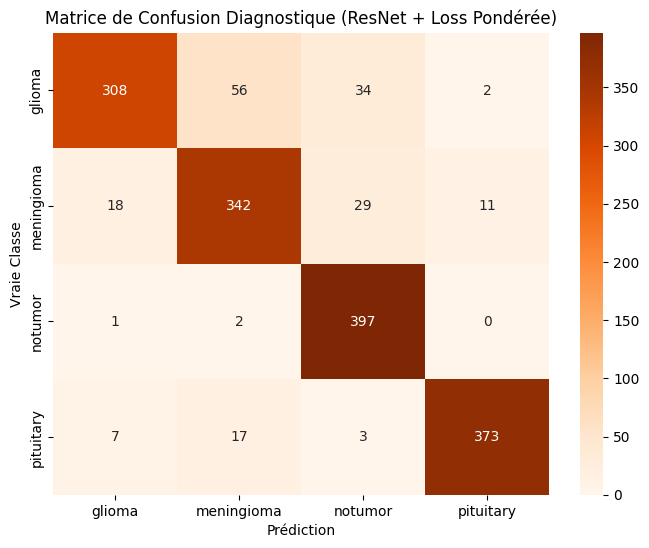

In [47]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 1. Chargement rigoureux des poids de l'époque 7
model.load_state_dict(torch.load('meilleur_modele_resnet_cropped.pth'))
model.eval()

y_true = []
y_pred = []

# 2. Inférence silencieuse
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

# 3. Récupération des classes et rapport
classes = ['glioma', 'meningioma', 'notumor', 'pituitary']

print("=== RAPPORT DE CLASSIFICATION RESNET ===")
print(classification_report(y_true, y_pred, target_names=classes))

# 4. Matrice comparative
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=classes, yticklabels=classes)
plt.ylabel('Vraie Classe')
plt.xlabel('Prédiction')
plt.title('Matrice de Confusion Diagnostique (ResNet + Loss Pondérée)')
plt.show()